# Initial classification baseline (from Module 20.1)

**Question:** Can the incident details help identify records with an arrest?
This notebook gives a simple first model and compares it with always predicting
no arrest.

Run the cleaning, EDA and feature-engineering notebooks first. The model uses the
numeric features created there. Training uses 2010-2019, and testing uses 2020
through February 2024. The results apply only to this copy of the data.

In [1]:
# load the tools for a simple reference comparison
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.metrics import ConfusionMatrixDisplay

In [2]:
# check the prepared tables before fitting the baseline
train_df = pd.read_parquet('../data/model_train_time_split.parquet')
test_df = pd.read_parquet('../data/model_test_time_split.parquet')
assert train_df.columns.equals(test_df.columns), 'Mismatched feature schema'
assert not train_df.isnull().any().any(), 'Missing training values'
assert not test_df.isnull().any().any(), 'Missing test values'
print(f'Training-period rows: {len(train_df):,}; test rows: {len(test_df):,}')

Training-period rows: 2,075,293; test rows: 913,641


## Baseline model

Logistic regression is a simple model that is easy to explain. I use a random
sample of **100,000 rows from the training period** and test the model on all
held-out test rows. The training results below describe this sample, not the
full training data.

Recorded arrests are uncommon, so I use balanced class weights. The decision
threshold is 0.5. I do not change it based on the test results. This can find
more arrests, but it can also create more false positives.

**Main metric: recall**, which shows the share of recorded arrests that the model
finds. I also report **precision**, which shows how many positive predictions were
recorded arrests. Accuracy is included for context because always predicting no
arrest can still give a high accuracy.

In [3]:
# sample training rows and exclude date metadata from the inputs
fit_df = train_df.sample(n=min(100000, len(train_df)), random_state=42)
X_train = fit_df.drop('Arrested', axis=1).select_dtypes(include='number')
y_train = fit_df['Arrested']
X_test = test_df.drop('Arrested', axis=1).select_dtypes(include='number')
y_test = test_df['Arrested']
print(f'Fit sample: {len(X_train):,}; predictors: {X_train.shape[1]}')
print(f'Fit arrest fraction: {y_train.mean():.4f}')
print(f'Test arrest fraction: {y_test.mean():.4f}')

Fit sample: 100,000; predictors: 73
Fit arrest fraction: 0.1110
Test arrest fraction: 0.0940


In [4]:
# fit scaling on the training sample only, keeping test rows unseen
pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('lgr', LogisticRegression(
        class_weight='balanced', solver='liblinear', max_iter=1000, random_state=42))
])
pipe.fit(X_train, y_train)
assert pipe.named_steps['lgr'].n_iter_.max() < 1000, 'Solver reached iteration limit'
train_preds = pipe.predict(X_train)
test_preds = pipe.predict(X_test)

In [5]:
# compare with always predicting no arrest on the same rows
results = []
for model_name, split, target, preds in [
    ('No-arrest reference', 'Fit sample', y_train, np.zeros(len(y_train), dtype=int)),
    ('No-arrest reference', 'Test', y_test, np.zeros(len(y_test), dtype=int)),
    ('Logistic regression', 'Fit sample', y_train, train_preds),
    ('Logistic regression', 'Test', y_test, test_preds)
]:
    results.append([
        model_name, split, len(target), accuracy_score(target, preds),
        precision_score(target, preds, zero_division=0), recall_score(target, preds)
    ])
# keep precision and recall visible because accuracy can be misleading
results_df = pd.DataFrame(
    results, columns=['Model', 'Split', 'Rows', 'Accuracy', 'Precision', 'Recall'])
results_df.round(4)

,Model,Split,Rows,Accuracy,Precision,Recall
0,No-arrest reference,Fit sample,100000,0.8890,0.0000,0.0000
1,No-arrest reference,Test,913641,0.9060,0.0000,0.0000
2,Logistic regression,Fit sample,100000,0.6797,0.2165,0.7202
3,Logistic regression,Test,913641,0.6741,0.1858,0.7297


The no-arrest reference has no positive predictions, so its precision is reported
as zero. Its recall is also zero. This gives a simple comparison with the trained
model. Training-sample results may be better than results on new data.

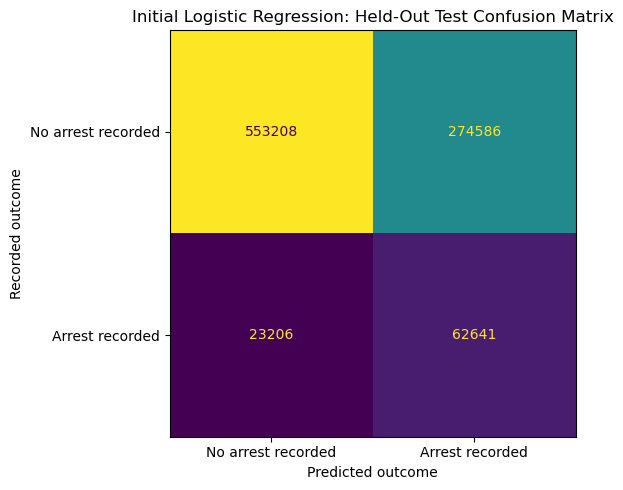

In [6]:
fig, ax = plt.subplots(figsize=(7, 5))
# show false alarms and missed arrests as counts on the test period
ConfusionMatrixDisplay.from_estimator(
    pipe, X_test, y_test, display_labels=['No arrest recorded', 'Arrest recorded'],
    values_format='d', colorbar=False, ax=ax)
ax.set_title('Initial Logistic Regression: Held-Out Test Confusion Matrix')
ax.set_xlabel('Predicted outcome')
ax.set_ylabel('Recorded outcome')
plt.tight_layout()
plt.savefig('../images/baseline_confusion_matrix.png', dpi=150)
plt.show()

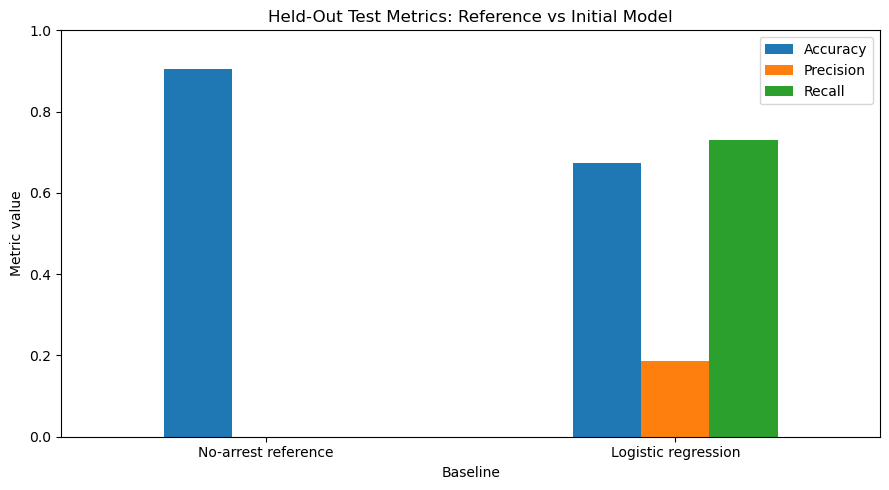

In [7]:
# compare held-out metrics to show what the model adds to the reference
test_results = results_df[results_df['Split'] == 'Test'].set_index('Model')
fig, ax = plt.subplots(figsize=(9, 5))
test_results[['Accuracy', 'Precision', 'Recall']].plot(kind='bar', ax=ax, rot=0)
ax.set_title('Held-Out Test Metrics: Reference vs Initial Model')
ax.set_xlabel('Baseline')
ax.set_ylabel('Metric value')
ax.set_ylim(0, 1)
plt.tight_layout()
plt.savefig('../images/baseline_metric_comparison.png', dpi=150)
plt.show()

In [8]:
# express test errors in plain terms
test_precision = precision_score(y_test, test_preds, zero_division=0)
test_recall = recall_score(y_test, test_preds)
false_positives = int(((test_preds == 1) & (y_test == 0)).sum())
missed_arrests = int(((test_preds == 0) & (y_test == 1)).sum())
print(f'Recorded arrests identified: {test_recall:.1%}')
print(f'Positive predictions with a recorded arrest: {test_precision:.1%}')
print(f'False positives: {false_positives:,}; missed recorded arrests: {missed_arrests:,}')

Recorded arrests identified: 73.0%
Positive predictions with a recorded arrest: 18.6%
False positives: 274,586; missed recorded arrests: 23,206


## Interpretation and limitations

Recall and precision should be read together. Finding more recorded arrests is not
enough if many positive predictions are wrong. The confusion matrix shows these
counts. Accuracy alone can look good because most records have no arrest recorded.

This is a first baseline, not an optimized model or a causal analysis. The test
period differs from training in time, crime mix and record maturity. The labels
show the status in this data snapshot, not what will happen later. Demographic
variables may also reflect differences in reporting and enforcement, so these
predictions should not be used for individual policing decisions.

Next steps are to use a time-based validation period, check results across
demographic groups and compare other models. The test scores should not be used
to tune the model.